In [37]:
#Adam Shinkle
#Assignment 2: Testing data analysis skills with pandas, numpy, and matplotlib. Use the dataset from the zip file.
#Total points: 24

#You are allowed to seek help from your classmates; however, it should be your own work.
#You can not copy or paste their work. If you seek help, you need to acknowledge it in your submission.
#You will submit the commented and outputs-printed Jupyter Notebook file

#Remove all unnecessary code and outputs. 


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix #You may or may not need

In [4]:
#Question 1: Report any data limitations. Your response must be generated using Python code; do not calculate or analyze this manually. (1 point)
data = pd.read_csv('used_device_data.csv')
data.head()

,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,146.0,2020,127,4.307572,4.715100
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,213.0,2020,325,5.162097,5.519018
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,213.0,2020,162,5.111084,5.884631
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,480.0,2020,345,5.135387,5.630961
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,185.0,2020,293,4.389995,4.947837


In [5]:
data.columns

Index(['device_brand', 'os', 'screen_size', '4g', '5g', 'rear_camera_mp',
       'front_camera_mp', 'internal_memory', 'ram', 'battery', 'weight',
       'release_year', 'days_used', 'normalized_used_price',
       'normalized_new_price'],
      dtype='str')

In [6]:
data.tail()

,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
3449,Asus,Android,15.34,yes,no,NaN,8.0,64.0,6.0,5000.0,190.0,2019,232,4.492337,6.483872
3450,Asus,Android,15.24,yes,no,13.0,8.0,128.0,8.0,4000.0,200.0,2018,541,5.037732,6.251538
3451,Alcatel,Android,15.80,yes,no,13.0,5.0,32.0,3.0,4000.0,165.0,2020,201,4.357350,4.528829
3452,Alcatel,Android,15.80,yes,no,13.0,5.0,32.0,2.0,4000.0,160.0,2020,149,4.349762,4.624188
3453,Alcatel,Android,12.83,yes,no,13.0,5.0,16.0,2.0,4000.0,168.0,2020,176,4.132122,4.279994


In [7]:
data.shape

(3454, 15)

In [8]:
data.dtypes

device_brand                 str
os                           str
screen_size              float64
4g                           str
5g                           str
rear_camera_mp           float64
front_camera_mp          float64
internal_memory          float64
ram                      float64
battery                  float64
weight                   float64
release_year               int64
days_used                  int64
normalized_used_price    float64
normalized_new_price     float64
dtype: object

In [9]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3454 entries, 0 to 3453
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   device_brand           3454 non-null   str    
 1   os                     3454 non-null   str    
 2   screen_size            3454 non-null   float64
 3   4g                     3454 non-null   str    
 4   5g                     3454 non-null   str    
 5   rear_camera_mp         3275 non-null   float64
 6   front_camera_mp        3452 non-null   float64
 7   internal_memory        3450 non-null   float64
 8   ram                    3450 non-null   float64
 9   battery                3448 non-null   float64
 10  weight                 3447 non-null   float64
 11  release_year           3454 non-null   int64  
 12  days_used              3454 non-null   int64  
 13  normalized_used_price  3454 non-null   float64
 14  normalized_new_price   3454 non-null   float64
dtypes: float64(9), 

In [10]:
nan_count = data.isnull().sum().sum()
print('Number of NaN values:', nan_count)

Number of NaN values: 202


In [11]:
#This dataset has 202 NaN entries. Null values are in columns rear_camer_mp, front_camera_mp, internal_memory, ram, battery, and weight. 
null_columns = data.isnull().sum()
print(null_columns[null_columns > 0])

rear_camera_mp     179
front_camera_mp      2
internal_memory      4
ram                  4
battery              6
weight               7
dtype: int64


count    3275.000000
mean        9.460208
std         4.815461
min         0.080000
25%         5.000000
50%         8.000000
75%        13.000000
max        48.000000
Name: rear_camera_mp, dtype: float64


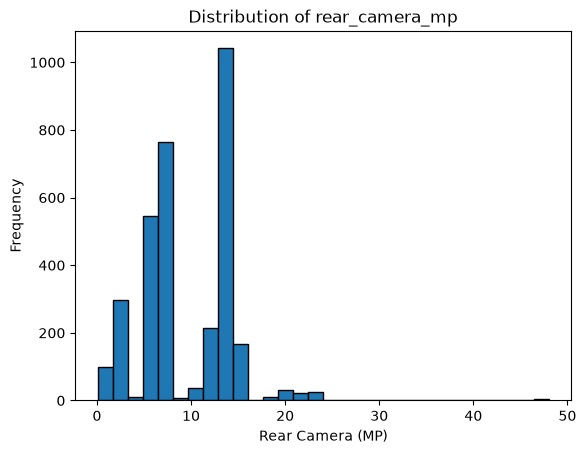

In [12]:
# Checking the distribution of rear_camera_mp before deciding how to fill missing values
print(data['rear_camera_mp'].describe())

plt.hist(data['rear_camera_mp'].dropna(), bins=30, edgecolor='black')
plt.title('Distribution of rear_camera_mp')
plt.xlabel('Rear Camera (MP)')
plt.ylabel('Frequency')
plt.show()

In [13]:
# Cleaning the data prior to proceeding.
# The mean (~9.46) is higher than the median (~8), and there's a long tail up to 48MP.
# This means the distribution is right-skewed, so the median is a better choice than
# the mean for imputation, since the mean is being pulled upward by high-MP outliers.

# Impute missing rear_camera_mp values with the median (robust to skew)
median_rear_camera = data['rear_camera_mp'].median()
data['rear_camera_mp'] = data['rear_camera_mp'].fillna(median_rear_camera)

# The remaining columns (front_camera_mp, internal_memory, ram, battery, weight)
# have very few missing values combined (~22 rows out of 3454), so we drop those rows
# rather than impute, since the loss of data is negligible.
data = data.dropna()

# Sanity check: confirm there are no more missing values
print('Remaining NaN values:', data.isnull().sum().sum())
print('New shape of dataset:', data.shape)

Remaining NaN values: 0
New shape of dataset: (3432, 15)


In [ ]:
#Commenting on Limitations
#NaN values have been normalized or columns deleted in several rows. 
#rear_camera_mp has used the median to normalize the data. This may effect results.
#NaN values in front_camera_mp, internal_memory, ram, battery, weight have led to deleting 22 columns.

In [14]:
#Question 2: Comment on outliers using visualization. (2 points)

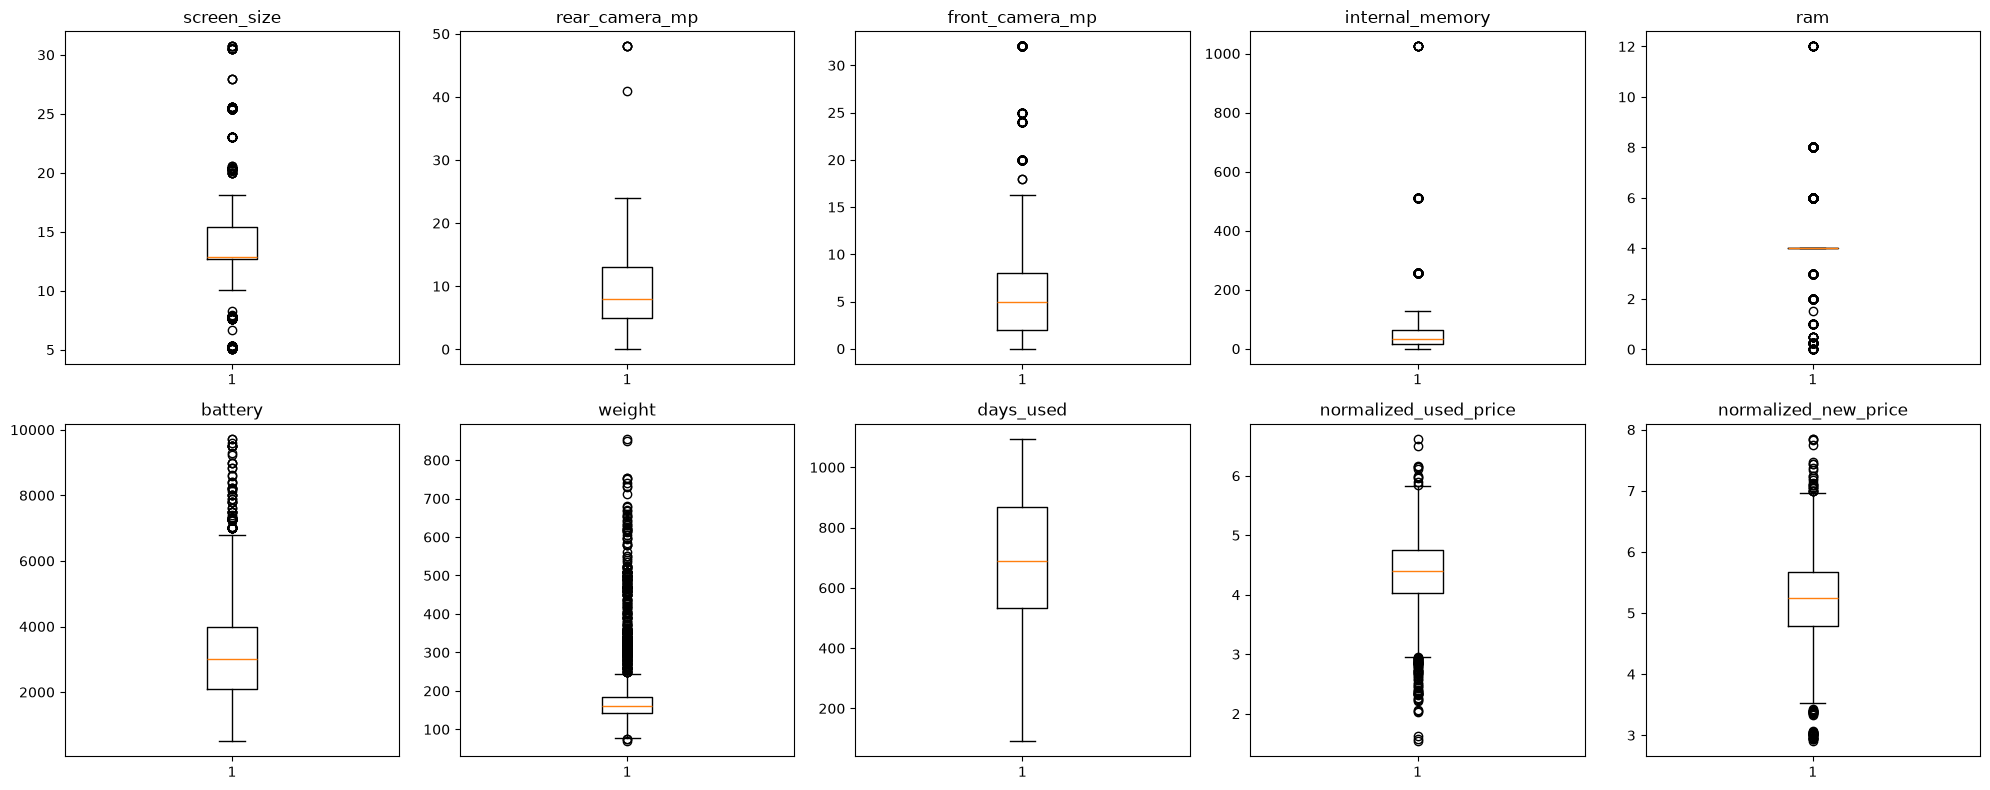

In [15]:
# Select the numeric columns worth checking for outliers
numeric_cols = ['screen_size', 'rear_camera_mp', 'front_camera_mp', 'internal_memory',
                 'ram', 'battery', 'weight', 'days_used', 'normalized_used_price',
                 'normalized_new_price']

fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].boxplot(data[col])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

In [35]:
# The column days-used appears to have 0 outliers showingg that usage duration is fairly consistent across the devices.
# Several columns show clear outliers internal_memory has a max of more than 1000 GB (vs. a typical upper
# bound of what looks to be around 140 GB), weight has a max of more than 800g (vs. ~250g), and battery has a max of
# nearly 10,000 mAh (vs. ~7000 mAh). These could point to a distinct device type rather than data error.

In [17]:
#Question 3: Create a new column device_age that represents the age of the device in years. Print the mean device age. (1 point)

# Create device_age by converting days_used into years, rounded to 2 decimal places.
# This gives a precise, per-device age based on actual usage time

data['device_age'] = round(data['days_used'] / 365, 2)

# Print the mean device age
mean_age = data['device_age'].mean()
print('Mean device age (years):', mean_age)

Mean device age (years): 1.8475903263403264


In [18]:
#Question 4: Now, start using numpy functions to generate insights from the data
#Question 4a: Calculate the average, minimum, and maximum values of days_used using numpy and print them.  (1 point)

avg_days = np.mean(data['days_used'])
min_days = np.min(data['days_used'])
max_days = np.max(data['days_used'])

print('Average days used:', avg_days)
print('Minimum days used:', min_days)
print('Maximum days used:', max_days)

Average days used: 674.3854895104895
Minimum days used: 91
Maximum days used: 1094


In [19]:
#Question 4b: Calculate and print standard deviation and variance of normalized_used_price. (1 point)

# Calculate standard deviation and variance of normalized_used_price using numpy
std_price = np.std(data['normalized_used_price'])
var_price = np.var(data['normalized_used_price'])

print('Standard deviation:', std_price)
print('Variance:', var_price)

Standard deviation: 0.584617166559632
Variance: 0.3417772314362125


In [20]:
#Question 4c: Calculate the 25th, 50th, and 75th percentiles of normalized_new_price and normalized_used_price. (1 point)

# Calculate the 25th, 50th, and 75th percentiles using numpy
new_price_percentiles = np.percentile(data['normalized_new_price'], [25, 50, 75])
used_price_percentiles = np.percentile(data['normalized_used_price'], [25, 50, 75])

print('normalized_new_price percentiles (25th, 50th, 75th):', new_price_percentiles)
print('normalized_used_price percentiles (25th, 50th, 75th):', used_price_percentiles)

normalized_new_price percentiles (25th, 50th, 75th): [4.79113095 5.24652392 5.6741648 ]
normalized_used_price percentiles (25th, 50th, 75th): [4.03720085 4.4065363  4.75793412]


In [21]:
#Question 4d: Count the number of devices in the data that have a normalized used price of less than 4.5. (1 point)

# Count the number of devices with normalized_used_price less than 4.5
count_below_4_5 = np.sum(data['normalized_used_price'] < 4.5)
print('Number of devices with normalized_used_price < 4.5:', count_below_4_5)

Number of devices with normalized_used_price < 4.5: 1983


In [22]:
#Question 5: We often deal with massive datasets. In such cases, sampling is a useful approach. 
#Randomly sample 500 devices from the dataset and calculate the average normalized_used_price and print. (1 point)

# Set a random seed so the sample is reproducible each time this cell is run
np.random.seed(42)

# Randomly sample 500 devices from the dataset
sample = data.sample(n=500, random_state=42)

# Calculate the average normalized_used_price of the sample
sample_avg_price = np.mean(sample['normalized_used_price'])
print('Average normalized_used_price of 500-device sample:', sample_avg_price)

Average normalized_used_price of 500-device sample: 4.3522272190299995


In [23]:
# Compare to the full dataset average to check how close the sample estimate is
full_avg_price = np.mean(data['normalized_used_price'])
print('Average normalized_used_price of full dataset:', full_avg_price)

Average normalized_used_price of full dataset: 4.368436845520396


In [24]:
#Question 7a: Calculate the z-scores of normalized_used_price to identify outliers. 
#You can use 3 standard deviations to identify outliers. 
#Print the number of outliers. (2 points)

# Calculate the mean and standard deviation of normalized_used_price
mean_price = np.mean(data['normalized_used_price'])
std_price = np.std(data['normalized_used_price'])

# Calculate z-scores: how many standard deviations each value is from the mean
data['z_score'] = (data['normalized_used_price'] - mean_price) / std_price

# Flag outliers as any device with a z-score beyond +/- 3
outliers = data[np.abs(data['z_score']) > 3]

print('Number of outliers:', len(outliers))

Number of outliers: 33


In [25]:
# Question 7b: Continuing from 7a, you are now interested to know why these are outliers. 
    #You think that days_used, internal_memory, and weight could be the reasons. 
#Compare these three variables of your outliers and the whole data and print them. Comment on your results.
#Hint: Create a separate dataframe (subset) for the outliers. (3 points)

# Create a subset dataframe containing just the outliers identified in 7a
outlier_subset = data[np.abs(data['z_score']) > 3]

# Compare the means of days_used, internal_memory, and weight
comparison_cols = ['days_used', 'internal_memory', 'weight']

print('Outliers - mean values:')
print(outlier_subset[comparison_cols].mean())
print()
print('Whole dataset - mean values:')
print(data[comparison_cols].mean())

Outliers - mean values:
days_used          689.060606
internal_memory    177.489697
weight             142.054545
dtype: float64

Whole dataset - mean values:
days_used          674.385490
internal_memory     54.742672
weight             182.870455
dtype: float64


In [32]:
# Comment: days_used is fairly close between outliers and the whole dataset (~689 vs
# ~674 days), so usage duration does not appear to explain why these devices are priced
# as outliers. internal_memory, however, is more than 3x higher for outliers
# than the whole dataset (~177GB vs ~55GB) suggesting outlier devices tend to have higher
# storage. This explains the high-priced outliers pulling this average up.
# weight is actually lower for outliers than the whole dataset (~142g vs ~183g), showing that
# high-end phones tending to be lighter designs rather than bulkier, less expensive devices.

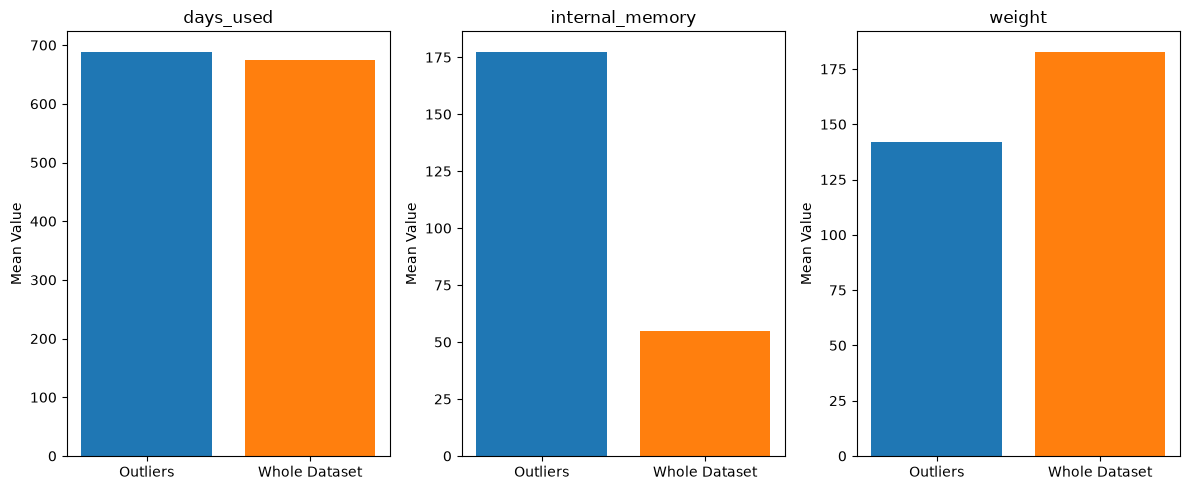

In [27]:
#Question 7c: Plot these comparions. You can choose the chart that you think will be more appropriate for visualization. (3 points)

# Plot comparison of outliers vs whole dataset for each variable, using separate
# subplots so each variable's own scale is visible (days_used is in the hundreds,
# while internal_memory and weight are on a much smaller scale)

comparison_cols = ['days_used', 'internal_memory', 'weight']
outlier_means = outlier_subset[comparison_cols].mean()
full_means = data[comparison_cols].mean()

fig, axes = plt.subplots(1, 3, figsize=(12, 5))

for i, col in enumerate(comparison_cols):
    axes[i].bar(['Outliers', 'Whole Dataset'],
                [outlier_means[col], full_means[col]],
                color=['tab:blue', 'tab:orange'])
    axes[i].set_title(col)
    axes[i].set_ylabel('Mean Value')

plt.tight_layout()
plt.show()

In [28]:
#Continue Case 2 with stattsmodels

In [29]:
#Question 8: Create a multiple linear regression model using the following independent variables
#internal_memory, battery, weight, days_used, 5g_yes
#Your dependent variable is normalized_used_price
#Explain the coefficients properly (4 points)

import statsmodels.api as sm

# Create 5g_yes: 1 if the device has 5G, 0 if not
data['5g_yes'] = (data['5g'] == 'yes').astype(int)

# Independent variables (x) and outcome variable (y)
x = data[['internal_memory', 'battery', 'weight', 'days_used', '5g_yes']]
y = data['normalized_used_price']

# Add the constant (intercept) term to the independent variables
x = sm.add_constant(x)

# Fit the multiple linear regression model and print the results
results = sm.OLS(y, x).fit()
print(results.summary())


                              OLS Regression Results                             
Dep. Variable:     normalized_used_price   R-squared:                       0.424
Model:                               OLS   Adj. R-squared:                  0.423
Method:                    Least Squares   F-statistic:                     504.8
Date:                   Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                           12:14:40   Log-Likelihood:                -2080.2
No. Observations:                   3432   AIC:                             4172.
Df Residuals:                       3426   BIC:                             4209.
Df Model:                              5                                         
Covariance Type:               nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const       

In [36]:
# Interpretation of coefficients (each one holds the other variables constant):
# - R-squared (0.424): these five variables explain about 42% of the variation in
#   normalized used price. The rest comes from factors not in the model (brand, release
#   year, RAM, cameras, etc.).
# - const (3.7035): the predicted normalized used price when all independent variables
#   are 0. It's a baseline value, not a realistic device.
# - internal_memory (+0.0004): each additional 1 GB of storage raises the predicted
#   normalized used price by about 0.0004 (about +0.04 per 100 GB). Statistically
#   significant (p < 0.05).
# - battery (+0.0003): each additional 1 mAh raises the predicted price by about
#   0.0003 (about +0.03 per 100 mAh). Significant, and it has the largest t-statistic,
#   suggesting it is a very strong predictor in the model.
# - weight (-0.0002): each additional gram is associated with a very small price
#   decrease, but its p-value (0.089) is above 0.05, so it is NOT statistically
#   significant. We can't conclude weight affects price once the other variables are
#   accounted for.
# - days_used (-0.0002): each additional day of use lowers the predicted price by
#   about 0.0002 (about -0.02 per 100 days), so more heavily used devices sell for less.
#   Significant.
# - 5g_yes (+0.4402): a 5G device is predicted to have a normalized used price about 0.4402
#   higher than a non-5G device with otherwise identical specs. Significant.

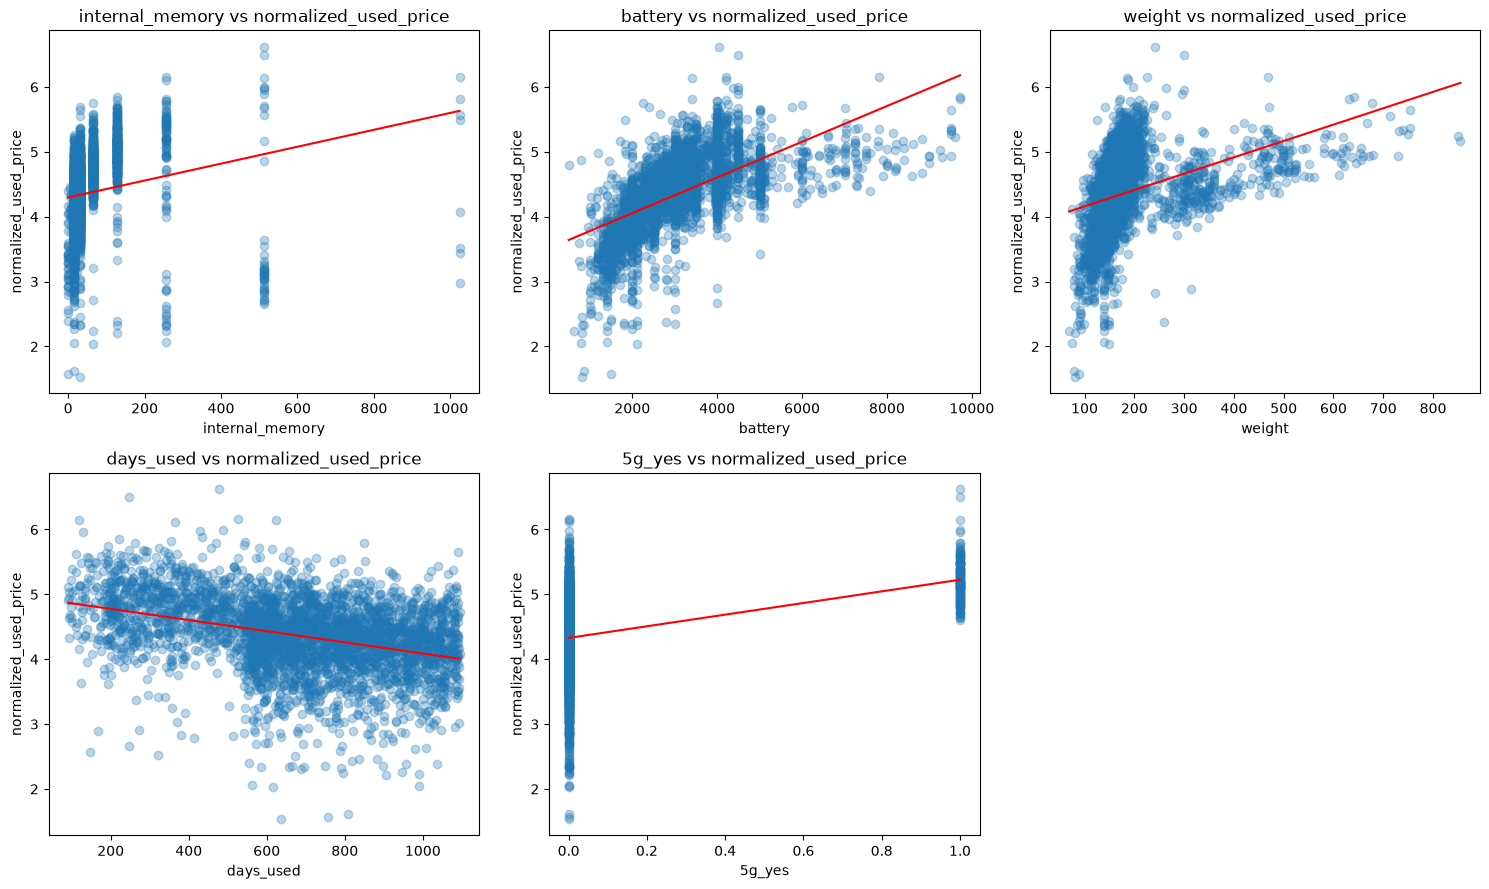

In [31]:
#Question 9:Develop scatterplots of each independent variable with the dependent variable with the regression lines.
# List of predictor variables (2 points)

# List of predictor variables
predictors = ['internal_memory', 'battery', 'weight', 'days_used', '5g_yes']

# One scatterplot per predictor against normalized_used_price
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(predictors):
    # Scatterplot (alpha makes overlapping points easier to see)
    axes[i].scatter(data[col], data['normalized_used_price'], alpha=0.3)

    # Fit a straight line (slope and intercept) and draw it in red
    slope, intercept = np.polyfit(data[col], data['normalized_used_price'], 1)
    x_line = np.linspace(data[col].min(), data[col].max(), 100)
    axes[i].plot(x_line, slope * x_line + intercept, color='red')

    axes[i].set_title(col + ' vs normalized_used_price')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('normalized_used_price')

# Hide the unused 6th subplot
axes[5].axis('off')

plt.tight_layout()
plt.show()